# Итоги лабораторных работ 1–5: сравнение алгоритмов

Здесь собраны результаты всех пяти работ. Во всех работах одинаковые данные, разбиения и метрики, поэтому цифры можно сравнивать напрямую.

| Задача | Данные | Основная метрика |
|---|---|---|
| Классификация жанра | GTZAN, 3-секундные фрагменты, разбиение по трекам | macro-F1 (больше — лучше) |
| Регрессия года выпуска | YearPredictionMSD, 50 000 / 10 000 песен | MAE в годах (меньше — лучше) |

Для каждого алгоритма есть четыре варианта:
* **sklearn baseline** — модель из sklearn с параметрами по умолчанию;
* **sklearn improved** — после проверки гипотез и подбора параметров;
* **custom baseline / custom improved** — своя реализация алгоритма в тех же условиях.

Все цифры ниже — на тестовой выборке, которая ни в одной работе не использовалась для выбора параметров. Метрики читаются из `results/*.json`, их сохраняет каждый ноутбук.

Загружаем результаты всех работ

In [1]:
import json, sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.append(str(ROOT))
from src.data import gtzan_split, msd_split
from src.results import RESULTS_DIR, classification_metrics, regression_metrics

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 4)

LABS = {"KNN": "lab1_knn", "Линейные модели": "lab2_linear", "Решающее дерево": "lab3_tree",
        "Случайный лес": "lab4_forest", "Градиентный бустинг": "lab5_boosting"}
VARIANTS = ["sklearn baseline", "sklearn improved", "custom baseline", "custom improved"]
raw = {name: json.loads((RESULTS_DIR / f"{f}.json").read_text()) for name, f in LABS.items()}

def table(task, metric):
    return pd.DataFrame({name: {v: r[task][v][metric] for v in VARIANTS} for name, r in raw.items()}).T

Точки отсчёта: самый частый класс и средний год

In [2]:
Xc_train, Xc_test, yc_train, yc_test, _, _ = gtzan_split()
Xr_train, Xr_test, yr_train, yr_test = msd_split()
most_frequent = pd.Series(yc_train).mode()[0]
const_c = classification_metrics(yc_test, np.full(len(yc_test), most_frequent))
const_r = regression_metrics(yr_test, np.full(len(yr_test), yr_train.mean()))
print(f"GTZAN, самый частый класс: macro-F1 = {const_c['f1_macro']:.3f}, accuracy = {const_c['accuracy']:.3f}")
print(f"MSD, средний год: MAE = {const_r['MAE']:.2f}, RMSE = {const_r['RMSE']:.2f}")

GTZAN, самый частый класс: macro-F1 = 0.012, accuracy = 0.065
MSD, средний год: MAE = 8.17, RMSE = 10.89


## 1. Классификация жанра (GTZAN)

macro-F1 и accuracy всех вариантов

In [3]:
f1, acc = table("classification", "f1_macro"), table("classification", "accuracy")
display(f1.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None).set_caption("macro-F1"))
display(acc.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None).set_caption("accuracy"))

,sklearn baseline,sklearn improved,custom baseline,custom improved
KNN,0.235,0.683,0.235,0.683
Линейные модели,0.139,0.676,0.177,0.676
Решающее дерево,0.487,0.531,0.501,0.534
Случайный лес,0.668,0.691,0.669,0.689
Градиентный бустинг,0.685,0.725,0.680,0.725


,sklearn baseline,sklearn improved,custom baseline,custom improved
KNN,0.228,0.677,0.228,0.677
Линейные модели,0.177,0.679,0.205,0.679
Решающее дерево,0.485,0.534,0.498,0.536
Случайный лес,0.670,0.697,0.671,0.695
Градиентный бустинг,0.686,0.727,0.680,0.728


## 2. Предсказание года выпуска (MSD)

MAE, RMSE и R² всех вариантов

In [4]:
mae, rmse, r2 = table("regression", "MAE"), table("regression", "RMSE"), table("regression", "R2")
display(mae.style.format("{:.2f}").background_gradient(cmap="Greens_r", axis=None).set_caption("MAE, лет"))
display(rmse.style.format("{:.2f}").background_gradient(cmap="Greens_r", axis=None).set_caption("RMSE, лет"))
display(r2.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None).set_caption("R²"))

,sklearn baseline,sklearn improved,custom baseline,custom improved
KNN,8.02,7.02,8.02,7.02
Линейные модели,6.88,6.33,6.88,6.33
Решающее дерево,9.65,6.49,9.66,6.49
Случайный лес,6.90,6.23,6.89,6.23
Градиентный бустинг,6.73,6.10,6.72,6.11


,sklearn baseline,sklearn improved,custom baseline,custom improved
KNN,10.99,9.86,10.99,9.86
Линейные модели,9.61,9.70,9.61,9.70
Решающее дерево,14.03,9.86,14.06,9.86
Случайный лес,9.55,9.60,9.55,9.60
Градиентный бустинг,9.43,9.40,9.43,9.44


,sklearn baseline,sklearn improved,custom baseline,custom improved
KNN,-0.019,0.180,-0.019,0.180
Линейные модели,0.220,0.206,0.220,0.206
Решающее дерево,-0.661,0.181,-0.666,0.181
Случайный лес,0.230,0.223,0.231,0.223
Градиентный бустинг,0.249,0.255,0.250,0.249


## 3. Бейзлайн и улучшенная версия

Сравнение бейзлайна и улучшенной версии по основным метрикам

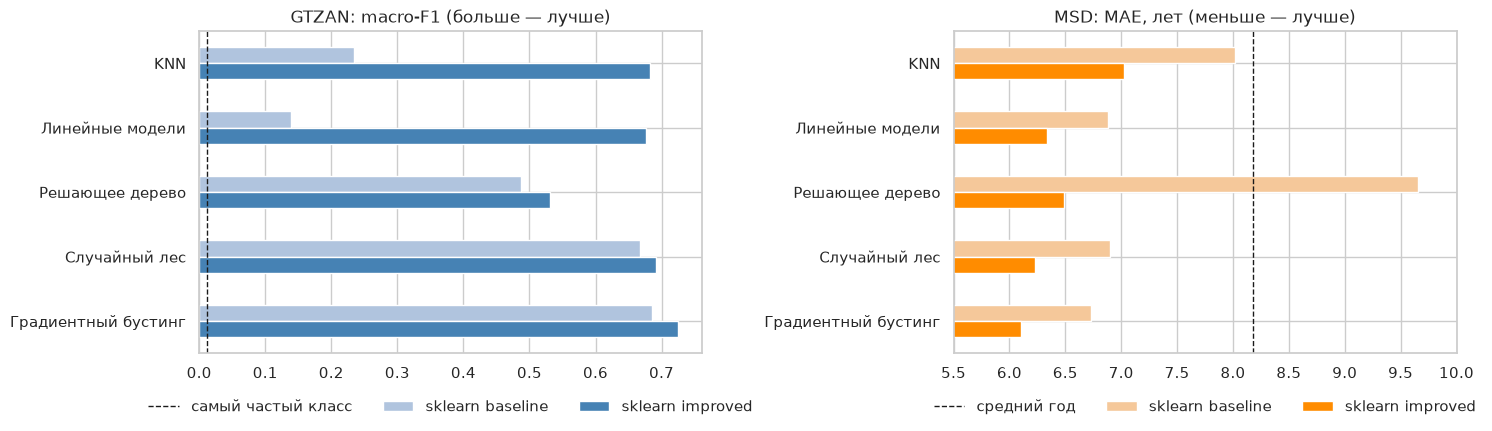

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
f1[["sklearn baseline", "sklearn improved"]].plot.barh(ax=axes[0], color=["#b0c4de", "steelblue"])
axes[0].axvline(const_c["f1_macro"], color="k", ls="--", lw=1, label="самый частый класс")
axes[0].set_title("GTZAN: macro-F1 (больше — лучше)")
mae[["sklearn baseline", "sklearn improved"]].plot.barh(ax=axes[1], color=["#f5c89a", "darkorange"])
axes[1].axvline(const_r["MAE"], color="k", ls="--", lw=1, label="средний год")
axes[1].set_xlim(5.5, 10); axes[1].set_title("MSD: MAE, лет (меньше — лучше)")
for ax in axes:
    ax.invert_yaxis(); ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, frameon=False)
plt.tight_layout(); plt.show()

Насколько улучшение изменило основную метрику

In [6]:
pd.DataFrame({
    "GTZAN: прирост macro-F1": f1["sklearn improved"] - f1["sklearn baseline"],
    "MSD: снижение MAE, лет": mae["sklearn baseline"] - mae["sklearn improved"],
}).style.format("{:+.3f}")

,GTZAN: прирост macro-F1,"MSD: снижение MAE, лет"
KNN,+0.448,+0.995
Линейные модели,+0.537,+0.549
Решающее дерево,+0.044,+3.163
Случайный лес,+0.023,+0.675
Градиентный бустинг,+0.040,+0.629


## 4. Свои реализации против sklearn

Разница между своей реализацией и sklearn в одинаковых условиях: ноль означает полное совпадение.

Разность «своя − sklearn» по основным метрикам

In [7]:
pd.DataFrame({
    "GTZAN macro-F1, бейзлайн": f1["custom baseline"] - f1["sklearn baseline"],
    "GTZAN macro-F1, улучш.": f1["custom improved"] - f1["sklearn improved"],
    "MSD MAE, бейзлайн": mae["custom baseline"] - mae["sklearn baseline"],
    "MSD MAE, улучш.": mae["custom improved"] - mae["sklearn improved"],
}).style.format("{:+.4f}")

,"GTZAN macro-F1, бейзлайн","GTZAN macro-F1, улучш.","MSD MAE, бейзлайн","MSD MAE, улучш."
KNN,+0.0000,+0.0000,+0.0000,+0.0000
Линейные модели,+0.0377,+0.0000,-0.0000,+0.0000
Решающее дерево,+0.0142,+0.0027,+0.0082,+0.0000
Случайный лес,+0.0008,-0.0020,-0.0093,-0.0004
Градиентный бустинг,-0.0047,-0.0001,-0.0147,+0.0123


Для детерминированных алгоритмов (KNN, линейная регрессия, дерево в регрессии) совпадение точное или до ошибок округления. Небольшие расхождения есть в трёх местах:
* **логистическая регрессия в бейзлайне** — на сырых признаках ни один оптимизатор не сходится, и результат зависит от того, где он остановился;
* **дерево в классификации** — выбор между разбиениями в точности одинакового качества;
* **случайный лес и бустинг** — случайность и бинирование.

Во всех улучшенных вариантах разница не больше 0.003 по macro-F1 и 0.02 года по MAE.

## 5. Итоговый рейтинг

Лучшие версии алгоритмов, отсортированные по основной метрике

In [8]:
best = pd.DataFrame({"GTZAN macro-F1 ↑": f1["sklearn improved"], "GTZAN accuracy ↑": acc["sklearn improved"],
                     "MSD MAE ↓": mae["sklearn improved"], "MSD R² ↑": r2["sklearn improved"]})
best["место GTZAN"] = best["GTZAN macro-F1 ↑"].rank(ascending=False).astype(int)
best["место MSD"] = best["MSD MAE ↓"].rank().astype(int)
best.sort_values("место GTZAN")

,GTZAN macro-F1 ↑,GTZAN accuracy ↑,MSD MAE ↓,MSD R² ↑,место GTZAN,место MSD
Градиентный бустинг,0.7252,0.7266,6.1019,0.2546,1,1
Случайный лес,0.6909,0.6965,6.2269,0.2231,2,2
KNN,0.6828,0.6765,7.0208,0.1805,3,5
Линейные модели,0.6763,0.6790,6.3337,0.2064,4,3
Решающее дерево,0.5314,0.5338,6.4885,0.1807,5,4


## 6. Что получилось

### Что сработало для каждого алгоритма

| Алгоритм | Главное в улучшении: классификация | Главное в улучшении: регрессия |
|---|---|---|
| KNN | масштабирование (QuantileTransformer), манхэттенское расстояние, k=10 | масштабирование, косинусное расстояние, k=30 |
| Линейные модели | масштабирование (без него не сходится), полиномиальные признаки с сильной регуляризацией | сплайны по признакам, логарифм таргета |
| Решающее дерево | признаки LDA | ограничение сложности (листья от 200 песен), признаки PLS, логарифм таргета |
| Случайный лес | признаки LDA, больше деревьев | признаки PLS, логарифм таргета, небольшие листья |
| Градиентный бустинг | гистограммная реализация, крупнее деревья, больше итераций | то же плюс меньший темп, логарифм таргета, признаки PLS |

### Общие наблюдения

1. **Разбиение данных важнее модели.** В GTZAN каждый трек нарезан на 10 фрагментов. Если раскладывать фрагменты в train и test случайно, KNN показывает 0.89 вместо честных 0.66, а OOB-оценка случайного леса завышена на 18 п.п. Все результаты здесь получены с разбиением по трекам.
2. **Предобработка нужна не всем.** Для KNN и логистической регрессии масштабирование — разница между «не работает» и «работает». Деревьям и ансамблям оно не нужно, их результаты от монотонных преобразований не меняются.
3. **Работа с таргетом помогает всем моделям регрессии.** Год выпуска сильно скошен: большинство песен после 1990 года. Обучение на `log(2012 − year)` снизило MAE у линейной модели, дерева, леса и бустинга. Цена — немного больший RMSE: модели чаще ошибаются на редких старых записях.
4. **Проекции с учителем — дешёвый способ усилить деревья.** Компоненты LDA и PLS как дополнительные признаки дают деревьям «наклонные» разбиения. Это заметно помогло одиночному дереву и лесу. Бустингу помогли только PLS-признаки в регрессии, а LDA в классификации почти ничего не добавили.
5. **Ансамбли деревьев выигрывают, но отрыв на MSD небольшой.** На GTZAN бустинг заметно лучше остальных. На MSD бустинг, лес и линейная модель со сплайнами отличаются на десятые доли года. Похоже, 90 признаков тембра просто содержат ограниченную информацию о годе: R² у всех моделей не выше 0.3.
6. **Свои реализации** повторили результаты sklearn во всех пяти работах. Значит, выигрыш от улучшений связан с постановкой задачи — признаками, преобразованием таргета, гиперпараметрами, — а не с конкретной библиотекой.

### Что бы я выбрал на практике

* **Определение жанра:** градиентный бустинг. Он на 3–5 п.п. macro-F1 точнее леса, KNN и логистической регрессии, быстро обучается в гистограммной версии и не требует масштабирования. Если важны простота и интерпретируемость, есть логистическая регрессия, но за это придётся заплатить заметной потерей качества.
* **Год выпуска:** тоже бустинг. Но линейная модель со сплайнами всего немного хуже, при этом она в разы проще и быстрее, так что для продакшена я бы всерьёз рассматривал и её.